# YOLOv8n retrain on the medium processed dataset

The first baseline (notebook 03) trained YOLOv8n for a fixed 30 epochs on a 277-image
training set, and was still improving (val loss and mAP50 still trending better) when
it stopped -- it hadn't converged. Its confusion matrix also showed the model mostly
**misses** damage rather than confusing classes, and produced background false
positives.

This notebook retrains YOLOv8n on `data/processed/RDD2022_4classes_medium`
(~1,000 train images, ~3.7x the original, plus explicit no-damage negative images),
with early stopping instead of a fixed epoch count, to see how much of the gap was
just data volume and training length.

In [1]:
from pathlib import Path
import yaml
import pandas as pd

from ultralytics import YOLO
import torch

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Dataset

`scripts/create_rdd2022_4classes_medium.py` already produced `data.yaml` with a
relative `path:` (fixing the absolute-path reproducibility issue from notebook 03),
so this notebook only needs to point at it.

In [2]:
DATASET_DIR = Path("../data/processed/RDD2022_4classes_medium")
DATA_YAML_PATH = DATASET_DIR / "data.yaml"

with open(DATA_YAML_PATH) as file:
    data_yaml = yaml.safe_load(file)

data_yaml

{'path': 'C:\\Users\\vl4di\\OneDrive - BUas\\GitHub\\Vladislav_Stoimenov_Graduation_Project_25_26\\data\\processed\\RDD2022_4classes_medium',
 'train': 'train/images',
 'val': 'val/images',
 'test': 'test/images',
 'names': {0: 'D00_Longitudinal_Crack',
  1: 'D10_Transverse_Crack',
  2: 'D20_Alligator_Crack',
  3: 'D40_Pothole'}}

## Dataset count and class distribution

Includes the no-damage negative images added in this iteration.

In [3]:
image_extensions = [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]
splits = ["train", "val", "test"]
class_names = data_yaml["names"]

summary_rows = []
class_counts = {split: {class_id: 0 for class_id in class_names} for split in splits}
negative_images = {split: 0 for split in splits}

for split in splits:
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"

    image_files = []
    for ext in image_extensions:
        image_files.extend(list(images_dir.glob(f"*{ext}")))

    label_files = list(labels_dir.glob("*.txt"))

    summary_rows.append({
        "split": split,
        "images": len(image_files),
        "labels": len(label_files),
    })

    for label_file in label_files:
        lines = [l for l in label_file.read_text(encoding="utf-8").splitlines() if l.strip()]

        if not lines:
            negative_images[split] += 1

        for line in lines:
            class_id = int(float(line.split()[0]))
            class_counts[split][class_id] += 1

summary_df = pd.DataFrame(summary_rows)
summary_df["no_damage_images"] = summary_df["split"].map(negative_images)
summary_df

,split,images,labels,no_damage_images
0,train,2068,1034,50
1,val,448,224,10
2,test,442,221,10


In [4]:
class_distribution_rows = []

for split in splits:
    for class_id, count in class_counts[split].items():
        class_distribution_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_names[class_id],
            "annotations": count,
        })

class_distribution_df = pd.DataFrame(class_distribution_rows)
class_distribution_df

,split,class_id,class_name,annotations
0,train,0,D00_Longitudinal_Crack,1011
1,train,1,D10_Transverse_Crack,650
2,train,2,D20_Alligator_Crack,510
3,train,3,D40_Pothole,569
4,val,0,D00_Longitudinal_Crack,278
5,val,1,D10_Transverse_Crack,129
6,val,2,D20_Alligator_Crack,106
7,val,3,D40_Pothole,119
8,test,0,D00_Longitudinal_Crack,217
9,test,1,D10_Transverse_Crack,124


## Training configuration

In [5]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    DEVICE = 0
else:
    DEVICE = "cpu"
    print("Using CPU")

CUDA available: True
GPU: NVIDIA GeForce RTX 2070 with Max-Q Design


In [6]:
MODEL_PATH = "../yolov8n.pt"

EPOCHS = 100       # upper bound; early stopping should end this sooner if it converges
PATIENCE = 20      # stop if val metrics don't improve for 20 epochs
IMAGE_SIZE = 640
BATCH_SIZE = 16    # bigger than the first baseline (8); more data, same GPU

PROJECT_DIR = "runs/road_damage_medium"
RUN_NAME = "yolov8n_medium_first_train"

print("Model path:", MODEL_PATH)
print("Epochs (max):", EPOCHS)
print("Patience:", PATIENCE)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Device:", DEVICE)
print("Data YAML:", DATA_YAML_PATH)

Model path: ../yolov8n.pt
Epochs (max): 100
Patience: 20
Image size: 640
Batch size: 16
Device: 0
Data YAML: ..\data\processed\RDD2022_4classes_medium\data.yaml


## Load YOLOv8n and train

In [7]:
model = YOLO(MODEL_PATH)

In [8]:
train_results = model.train(
    data=str(DATA_YAML_PATH),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=2,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.81 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.48  Python-3.10.20 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2070 with Max-Q Design, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=..\data\processed\RDD2022_4classes_medium\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../yolov8n.pt,

## Test set evaluation

Same procedure as notebook 03, on the held-out test split.

In [9]:
RUN_DIR = model.trainer.save_dir  # actual save dir; project/name can be nested/suffixed by Ultralytics

best_model = YOLO(str(RUN_DIR / "weights" / "best.pt"))

test_metrics = best_model.val(
    data=str(DATA_YAML_PATH),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
)

Ultralytics 8.4.48  Python-3.10.20 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2070 with Max-Q Design, 8192MiB)
Model summary (fused): 73 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.20.0 ms, read: 13.21.1 MB/s, size: 81.7 KB)
val: Scanning C:\Users\vl4di\OneDrive - BUas\GitHub\Vladislav_Stoimenov_Graduation_Project_25_26\data\processed\RDD2022_4classes_medium\test\labels... 221 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 221/221 624.3it/s 0.4s
val: New cache created: C:\Users\vl4di\OneDrive - BUas\GitHub\Vladislav_Stoimenov_Graduation_Project_25_26\data\processed\RDD2022_4classes_medium\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 3.8it/s 3.7s
                   all        221        573      0.503      0.434      0.424      0.194
D00_Longitudinal_Crack        103        217      0.428      0.332      0.297      0.141
  D10_Transverse_Crack       

In [10]:
precision = test_metrics.box.mp
recall = test_metrics.box.mr
map50 = test_metrics.box.map50
map50_95 = test_metrics.box.map

f1_score = 2 * (precision * recall) / (precision + recall + 1e-9)

test_metrics_df = pd.DataFrame([
    {
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1_score,
        "mAP@50": map50,
        "mAP@50:95": map50_95,
    }
])

test_metrics_df

,Precision,Recall,F1-score,mAP@50,mAP@50:95
0,0.502827,0.434453,0.466146,0.424237,0.193696


## Training curves and overfitting check

Epochs run: 100 (max was 100, patience 20)
Best validation loss: 5.8254
Best validation F1-score: 0.4634
Best validation mAP@50: 0.4171
Best validation mAP@50:95: 0.1843


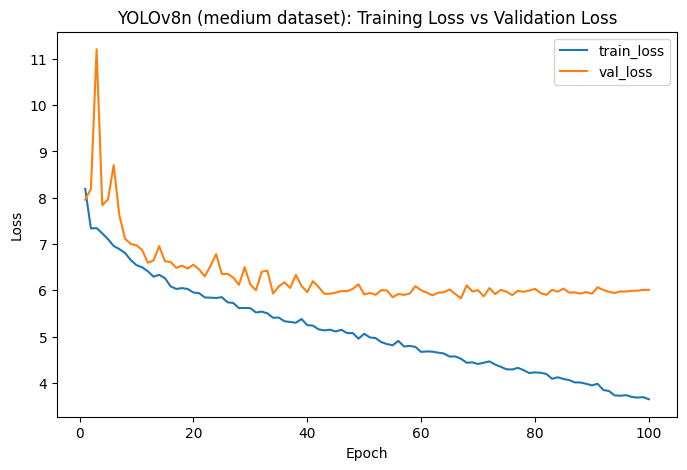

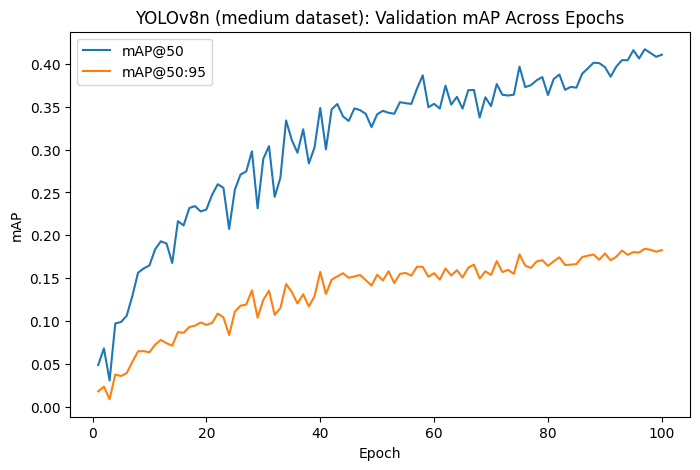

In [11]:
results_path = RUN_DIR / "results.csv"

results_df = pd.read_csv(results_path)
results_df.columns = results_df.columns.str.strip()

epochs = np.arange(1, len(results_df) + 1)

results_df["train_loss"] = (
    results_df["train/box_loss"] + results_df["train/cls_loss"] + results_df["train/dfl_loss"]
)
results_df["val_loss"] = (
    results_df["val/box_loss"] + results_df["val/cls_loss"] + results_df["val/dfl_loss"]
)
results_df["val_f1"] = (
    2 * results_df["metrics/precision(B)"] * results_df["metrics/recall(B)"]
    / (results_df["metrics/precision(B)"] + results_df["metrics/recall(B)"] + 1e-9)
)

print(f"Epochs run: {len(results_df)} (max was {EPOCHS}, patience {PATIENCE})")
print(f"Best validation loss: {results_df['val_loss'].min():.4f}")
print(f"Best validation F1-score: {results_df['val_f1'].max():.4f}")
print(f"Best validation mAP@50: {results_df['metrics/mAP50(B)'].max():.4f}")
print(f"Best validation mAP@50:95: {results_df['metrics/mAP50-95(B)'].max():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["train_loss"], label="train_loss")
plt.plot(epochs, results_df["val_loss"], label="val_loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLOv8n (medium dataset): Training Loss vs Validation Loss")
plt.savefig("medium_loss_curve.png", bbox_inches="tight")
plt.close()
display(Image(filename="medium_loss_curve.png"))

plt.figure(figsize=(8, 5))
plt.plot(epochs, results_df["metrics/mAP50(B)"], label="mAP@50")
plt.plot(epochs, results_df["metrics/mAP50-95(B)"], label="mAP@50:95")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLOv8n (medium dataset): Validation mAP Across Epochs")
plt.savefig("medium_map_curve.png", bbox_inches="tight")
plt.close()
display(Image(filename="medium_map_curve.png"))

## Comparison with the first baseline

`small` is the original 277-image baseline from notebook 03 (test split, 60 images).
`medium` is this run (~1,000+ train images, with negatives, early stopping).

In [12]:
comparison_df = pd.DataFrame([
    {
        "dataset": "small (notebook 03)",
        "train_images": 277,
        "precision": 0.368,
        "recall": 0.305,
        "f1": 0.334,
        "mAP50": 0.297,
        "mAP50-95": 0.119,
    },
    {
        "dataset": "medium (this notebook)",
        "train_images": len(list((DATASET_DIR / "train" / "images").glob("*"))),
        "precision": precision,
        "recall": recall,
        "f1": f1_score,
        "mAP50": map50,
        "mAP50-95": map50_95,
    },
])

comparison_df

,dataset,train_images,precision,recall,f1,mAP50,mAP50-95
0,small (notebook 03),277,0.368000,0.305000,0.334000,0.297000,0.119000
1,medium (this notebook),1034,0.502827,0.434453,0.466146,0.424237,0.193696


## Notes

- If `Epochs run` above is well under 100, early stopping kicked in -- the model
  converged rather than being cut off mid-improvement like the first baseline.
- Check the new confusion matrix (`RUN_DIR / "weights"` sibling output) for whether
  D00 (longitudinal crack) recall improved, since that was the weakest class despite
  having the most training instances in the small baseline.
- This run still doesn't use the Faster R-CNN comparison (notebook 04) -- combine
  both result tables once notebook 04 has been run on this same dataset.